# SARIMAX

Сегодня прогнозируем суммарные продажи Favorita на **28 дней вперёд**. Такой прогноз помогает планировать поставки и нагрузку сети. Для заказа конкретного товара потребуется прогноз по товару и магазину.

## Подготовка

In [ ]:
%pip -q install prophet statsforecast statsmodels gdown pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 4.6 MB/s eta 0:00:00


In [ ]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import scipy.stats as stats
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image
from tqdm import tqdm

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import MSTL as MSTL_decomp

import prophet as fp
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import add_changepoints_to_plot

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, SeasonalNaive, MSTL, AutoTheta, HoltWinters

**StatsForecast** — библиотека Nixtla для статистических моделей. Удобна, когда нужно одинаково обучить и сравнить несколько моделей или обработать много рядов. **Prophet** рассмотрим отдельно: на его компонентах удобно разбирать тренд, сезонность и события.

[Документация StatsForecast](https://nixtlaverse.nixtla.io/statsforecast/index.html).
[Документация Prophet](https://facebook.github.io/prophet/docs/quick_start.html).

In [ ]:
def adf_test(timeseries):
    print("Results of Dickey-Fuller Test:")
    dftest = adfuller(timeseries, autolag="AIC")
    dfoutput = pd.Series(
        dftest[0:4],
        index=[
            "Test Statistic",
            "p-value",
            "#Lags Used",
            "Number of Observations Used",
        ],
    )
    for key, value in dftest[4].items():
        dfoutput["Critical Value (%s)" % key] = value
    print(dfoutput)

## Данные

Используем данные Favorita из предыдущей лекции: [продажи](https://drive.google.com/file/d/1xF5HXH0_fJlSr82A0nRehu6NVeq6mvhR/view), праздники и цены на нефть. Загрузим их следующей ячейкой.

Работаем с суммарными дневными продажами в **тысячах единиц**.

In [ ]:
import gdown

gdown.download(id='1xF5HXH0_fJlSr82A0nRehu6NVeq6mvhR', output='train_data.csv', quiet=True)
gdown.download(id='1D4rnInuBSKsYkaQl5yi9DKpUuKtrwIAQ', output='oil.csv', quiet=True)
gdown.download(id='1cWdWO8CevKUPU-vqU58MhGun6_Z8_9kA', output='holidays_events.csv', quiet=True)

'holidays_events.csv'

In [ ]:
sales_raw = pd.read_csv('train_data.csv', parse_dates=['date'])
sales_raw.head()

,date,city,state,store_type,family,sales
0,2013-01-01,Salinas,Santa Elena,D,BEAUTY,2.000
1,2013-01-01,Salinas,Santa Elena,D,BEVERAGES,810.000
2,2013-01-01,Salinas,Santa Elena,D,BREAD/BAKERY,180.589
3,2013-01-01,Salinas,Santa Elena,D,CLEANING,186.000
4,2013-01-01,Salinas,Santa Elena,D,DAIRY,143.000


Восстановим ежедневный календарь. В исходных данных нет 25 декабря: магазины закрыты на Рождество, поэтому продажи в эти дни принимаем равными нулю.

Начнём со 2 января 2013 года — первой доступной котировки нефти. Так у всех моделей будет одинаковая история.

In [ ]:
sales = sales_raw.groupby('date')['sales'].sum().sort_index().to_frame('y') / 1000
sales.index.name = 'ds'
sales = sales.asfreq('D')
christmas = (sales.index.month == 12) & (sales.index.day == 25)
sales.loc[christmas, 'y'] = sales.loc[christmas, 'y'].fillna(0)
sales = sales.loc['2013-01-02':]
sales.head()

,y
ds,
2013-01-02,496.092418
2013-01-03,361.429231
2013-01-04,354.459677
2013-01-05,477.350121
2013-01-06,519.695401


In [ ]:
fig = px.line(title='Продажи Favorita')
fig.add_scatter(x=sales.index, y=sales['y'], mode='lines', name='sales', line=dict(color='blue'))

fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_yaxes(title_text='Продажи, тыс. ед.')
fig.show()

Разделим данные по датам:

* **train:** 2 января 2013 — 3 декабря 2016. На нём обучаем модели в примерах.
* **valid:** 4–31 декабря 2016, следующие 28 дней. На нём смотрим, как изменения модели влияют на прогноз out-of-sample.
* **train_all = train + valid:** история до конца 2016 года. Используем для кросс-валидации и обучения итоговых моделей.
* **test:** 1–28 января 2017. Не используем при подборе; оценим прогноз на нём только в самом конце.

Valid нужен для первых экспериментов. Затем сравним модели на нескольких периодах внутри train_all с помощью кросс-валидации.

In [ ]:
forecast_horizon = 28
train_all = sales.loc[:'2016-12-31'].reset_index()
train = train_all.iloc[:-forecast_horizon].copy()
valid = train_all.iloc[-forecast_horizon:].copy()
test = sales.loc['2017-01-01':'2017-01-28'].reset_index()
train_size = len(train)

pd.DataFrame({'Начало': [train.ds.min(), valid.ds.min(), test.ds.min()],
              'Конец': [train.ds.max(), valid.ds.max(), test.ds.max()]},
             index=['train', 'valid', 'test'])

,Начало,Конец
train,2013-01-02,2016-12-03
valid,2016-12-04,2016-12-31
test,2017-01-01,2017-01-28


In [ ]:
fig = px.line(title='Продажи Favorita: история до test')
fig.add_scatter(x=train.ds, y=train['y'], mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=valid.ds, y=valid['y'], mode='lines', name='valid', line=dict(color='green'))
fig.add_scatter(x=test.ds, y=test['y'], mode='lines', name='test', line=dict(color='orange'))

fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_yaxes(title_text='Продажи, тыс. ед.')
fig.show()

## Seasonal Naive

**Сезонный наивный прогноз** (Seasonal Naive) повторяет последнее известное значение для соответствующей позиции внутри сезона:

$$\hat y_{T+h\mid T}=y_{T+h-m(k+1)},\qquad k=\left\lfloor\frac{h-1}{m}\right\rfloor,$$

где $T$ — последний момент обучения, $h$ — горизонт прогноза, $m$ — длина сезона.

Для месячных данных прогноз на будущий февраль равен последнему наблюдавшемуся значению февраля. Для дневных продаж с недельной сезонностью прогноз на каждую будущую субботу равен продажам в последнюю известную субботу.

Это простой ориентир (бейзлайн) для сравнения с другими моделями.

Качество прогноза оценим по MAE, RMSE, WAPE и MAPE. MAPE считаем только по дням с ненулевыми продажами: при нуле в знаменателе она не определена. Остальные метрики учитывают и эти дни.

Вынесем расчёт в функцию `forecast_errors`, чтобы использовать одинаковые метрики для всех моделей.

In [ ]:
def forecast_errors(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    error = actual - predicted
    nonzero = actual != 0
    # Обратите внимание, что в mape мы убрали точки, где знаменатель = 0
    mape = np.mean(np.abs(error[nonzero] / actual[nonzero])) * 100 if nonzero.any() else np.nan

    return {'MAE': np.abs(error).mean(),
            'RMSE': np.sqrt(np.mean(error ** 2)),
            'WAPE(%)': np.abs(error).sum() / np.abs(actual).sum() * 100,
            'MAPE(%)': mape}

Функция `check_on_valid` сравнивает прогноз с фактическими продажами на valid и выводит метрики. Также показывает изменение MAE относительно Seasonal Naive: отрицательное значение означает меньшую ошибку.

Передаём название модели, таблицу прогноза и название столбца с прогнозом: у Prophet это `yhat`, у AutoARIMA — `AutoARIMA`.

In [ ]:
validation_results = []

def check_on_valid(name, prediction, value_col='yhat'):
    prediction = prediction[['ds', value_col]].rename(columns={value_col: 'yhat'})
    aligned = valid[['ds', 'y']].merge(prediction, on='ds', validate='one_to_one')
    assert len(aligned) == len(valid) and aligned['yhat'].notna().all()
    row = {'Модель': name, **forecast_errors(aligned.y, aligned.yhat)}
    validation_results.append(row)
    display(pd.DataFrame([row]).set_index('Модель').round(2))
    if name != 'Seasonal Naive':
        print(f"Изменение MAE относительно наивного: {row['MAE'] - validation_results[0]['MAE']:+.2f} тыс. ед.")

Функция `plot_valid` делает визуализацию - показывает train синим, valid зелёным, прогноз красным. Время обучения и прогноза измерим в итоговом сравнении.

In [ ]:
def plot_valid(prediction, value_col='yhat', title='Прогноз на valid'):
    fig = px.line(title=title)
    fig.add_scatter(x=train.ds, y=train['y'], mode='lines', name='train', line=dict(color='blue'))
    fig.add_scatter(x=valid.ds, y=valid['y'], mode='lines', name='valid', line=dict(color='green'))
    fig.add_scatter(x=prediction['ds'], y=prediction[value_col], mode='lines', name='Прогноз', line=dict(color='red'))
    fig.update_layout(template='plotly_white', width=1000, height=450)
    fig.update_yaxes(title_text='Продажи, тыс. ед.')
    fig.show()

Для моделей StatsForecast у входного датасета должны быть 3 обязательных столбца:

* **y** — значения ряда.
* **ds** — даты наблюдений.
* **unique_id** — идентификатор ряда. Например, у каждой товарной группы может быть свой идентификатор.

У нас 1 ряд — суммарные продажи. Зададим ему `unique_id='sales'` во всех выборках.

Благодаря unique_id в одной таблице можно хранить много рядов. При этом StatsForecast обучает отдельную модель для каждого ряда, а не автоматически учитывает зависимости между ними.

In [ ]:
for data in [train, valid, train_all, test]:
    data['unique_id'] = 'sales'

In [ ]:
sf_naive = StatsForecast(models=[SeasonalNaive(season_length=7)], freq='D')
forecast_naive = sf_naive.forecast(df=train, h=forecast_horizon)

check_on_valid('Seasonal Naive', forecast_naive, 'SeasonalNaive')

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Seasonal Naive,254.02,394.56,25.43,19.29


In [ ]:
forecast_naive

,unique_id,ds,SeasonalNaive
0,sales,2016-12-04,1056.721592
1,sales,2016-12-05,752.583768
2,sales,2016-12-06,645.760508
3,sales,2016-12-07,767.361704
4,sales,2016-12-08,843.603314
5,sales,2016-12-09,853.452931
6,sales,2016-12-10,1113.440567
7,sales,2016-12-11,1056.721592
8,sales,2016-12-12,752.583768
9,sales,2016-12-13,645.760508


In [ ]:
plot_valid(forecast_naive, 'SeasonalNaive', 'Простой прогноз: seasonal naive')

🐀 **Когда Seasonal Naive может работать плохо?**

Если последняя неделя обучения попала на праздник (напр. 25 декабря), модель повторит праздничный всплеск и день с нулевыми продажами на обычной неделе.

Посмотрим на пример.

In [ ]:
dates_demo = pd.date_range('2024-01-01', periods=100)
sales_demo = 100 + 20 * np.sin(2 * np.pi * np.arange(70) / 7)
train_demo = sales_demo[:42].copy()
train_demo[-2] += 100  # Покупки перед праздником.
train_demo[-1] = 0     # Магазин закрыт.
forecast_demo = np.tile(train_demo[-7:], 4)

fig = px.line(title='Seasonal Naive повторяет и праздничные события последней недели')
fig.add_scatter(x=dates_demo[:42], y=train_demo, mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=dates_demo[42:], y=sales_demo[42:], mode='lines', name='valid', line=dict(color='green'))
fig.add_scatter(x=dates_demo[42:], y=forecast_demo, mode='lines', name='Seasonal Naive', line=dict(color='red'))
fig.update_layout(template='plotly_white', width=800, height=450)
fig.update_yaxes(title_text='Продажи, условные единицы')
fig.show()

## Декомпозиция

Перед более сложными моделями посмотрим на структуру продаж. Сделаем декомпозицию

🐀 **Какие длины сезонностей возьмем?**

С помощью MSTL выделим недельный цикл и годовой, как на прошлой лекции.

Праздники и два дня перед ними позже учтём отдельно.

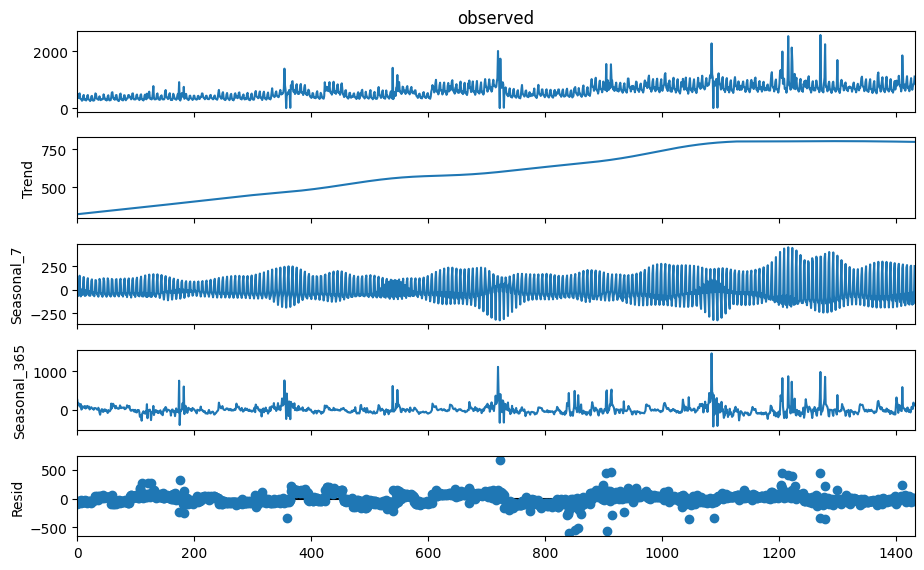

In [ ]:
mstl = MSTL_decomp(train['y'], periods=[7, 365])
res = mstl.fit()
fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

🐀 **Какими должны быть остатки после декомпозиции?**

Проверим остатки декомпозиции на автокорреляцию и стационарность.

In [ ]:
acorr_ljungbox(res.resid, return_df=True)

,lb_stat,lb_pvalue
1,358.605652,5.665012e-80
2,765.170434,7.004085e-167
3,1162.386257,1.061744e-251
4,1527.869096,0.000000e+00
5,1918.169226,0.000000e+00
6,2279.030810,0.000000e+00
7,2439.137353,0.000000e+00
8,2806.615736,0.000000e+00
9,3034.229062,0.000000e+00
10,3305.974100,0.000000e+00


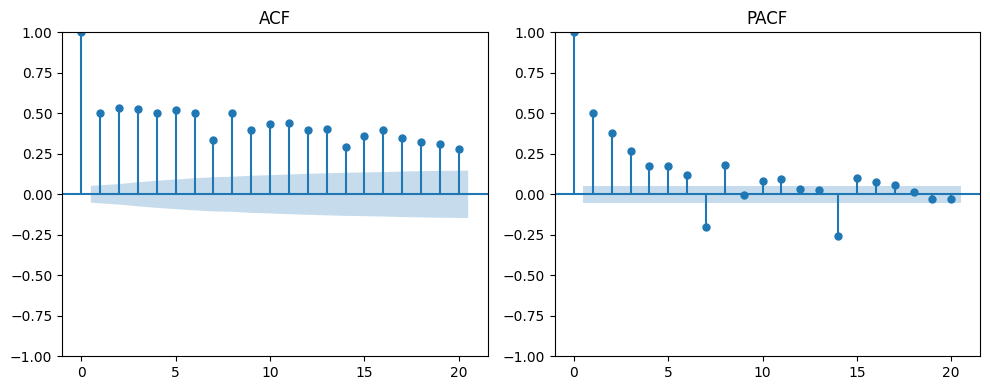

In [ ]:
# 2 графика рядом
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# ACF
plot_acf(res.resid.dropna(), ax=ax[0], lags=20)
ax[0].set_title('ACF')

# PACF
plot_pacf(res.resid.dropna(), ax=ax[1], lags=20)
ax[1].set_title('PACF')


plt.tight_layout()
plt.show()

In [ ]:
adf_test(res.resid)

Results of Dickey-Fuller Test:
Test Statistic                   -5.460772
p-value                           0.000003
#Lags Used                       20.000000
Number of Observations Used    1411.000000
Critical Value (1%)              -3.434993
Critical Value (5%)              -2.863591
Critical Value (10%)             -2.567862
dtype: float64


/tmp/ipykernel_4054/2607197953.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



🐀 **Что мы ожидаем от остатков?**

После удаления тренда и сезонности в остатках может сохраняться автокорреляция. Попробуем другой способ разложения: мультипликативную декомпозицию.

## Мультипликативная декомпозиция

Мы выполнили аддитивное разложение. Напомним два варианта:

**Аддитивное:**

$$y_t=T_t+S_t+R_t.$$

**Мультипликативное:**

$$y_t=T_t\cdot S_t\cdot R_t.$$

Здесь $T_t$ — тренд, $S_t$ — сезонность, $R_t$ — остаточная компонента.

Аддитивное разложение подходит, когда сезонные колебания примерно постоянны в единицах ряда. Мультипликативное — когда они пропорциональны уровню: например, разница между буднями и выходными составляет примерно одинаковый процент продаж, а не одинаковое число единиц.

![image.png](https://www.researchgate.net/publication/348592737/figure/fig2/AS:981645804961802@1611054006728/Examples-for-multiplicative-and-additive-relationship-between-time-series-components.png)

🐀 **Какая декомпозиция подойдет нашему временному ряду: аддитивная или мультипликативная?**

MSTL выполняет аддитивное разложение. Для мультипликативного воспользуемся логарифмом: он превращает произведение компонент в сумму.

$$y_t=T_t\cdot S_t\cdot R_t
\quad\Rightarrow\quad
\log y_t=\log T_t+\log S_t+\log R_t.$$

1. Возьмём логарифм ряда — все значения должны быть положительными.
2. Выполним аддитивное разложение логарифма с помощью MSTL.
3. Применим экспоненту к компонентам, чтобы получить мультипликативное разложение в исходном масштабе.

Логарифм нуля не определён. Только для этого примера заменим нули 25 декабря значениями между соседними днями. В данных для обучения моделей рождественские нули оставим.

In [ ]:
# Только для иллюстрации разложения уберём эффект закрытия магазинов.
# В данных для прогнозирования рождественские нули остаются.
decomp_y = train['y'].mask(train['y'].eq(0)).interpolate()
log_y = np.log(decomp_y)
px.line(x=train.ds, y=log_y, title='Логарифм продаж', template='plotly_white').show()

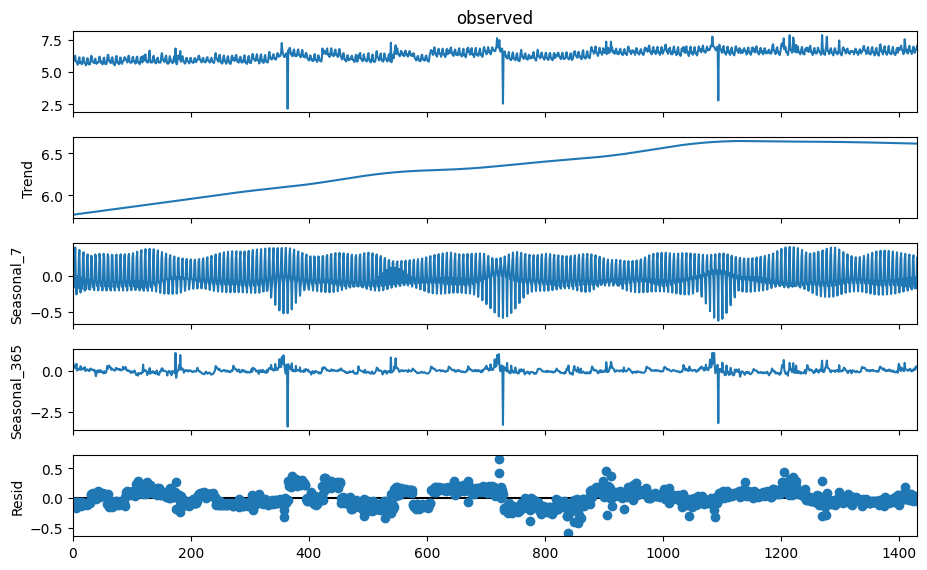

In [ ]:
mstl_multi = MSTL_decomp(log_y, periods=[7, 365])
res_multi = mstl_multi.fit()
fig = res_multi.plot()
fig.set_size_inches(10, 6)
plt.show()

**Обратное преобразование**

Если $z=\ln y$, то $y=e^z$.

Используем `np.exp()`: так можно вернуть в исходный масштаб и сам ряд, и каждую компоненту разложения.

Ниже проверим восстановление самого ряда. Получим продажи с подставленными значениями 25 декабря, а не с исходными нулями.

In [ ]:
pd.DataFrame({'Продажи для разложения': decomp_y, 'Восстановленные': np.exp(log_y)}).head()

,Продажи для разложения,Восстановленные
0,496.092418,496.092418
1,361.429231,361.429231
2,354.459677,354.459677
3,477.350121,477.350121
4,519.695401,519.695401


Проверим остатки разложения логарифма. Мультипликативная сезонность может лучше описывать ряд, но не обязана устранять всю автокорреляцию.

In [ ]:
acorr_ljungbox(res_multi.resid, return_df=True)

,lb_stat,lb_pvalue
1,891.941334,5.542255e-196
2,1711.147074,0.000000e+00
3,2519.988261,0.000000e+00
4,3277.557409,0.000000e+00
5,4035.651329,0.000000e+00
6,4736.158638,0.000000e+00
7,5274.177048,0.000000e+00
8,5870.524536,0.000000e+00
9,6405.408365,0.000000e+00
10,6920.148816,0.000000e+00


In [ ]:
adf_test(res_multi.resid)

Results of Dickey-Fuller Test:
Test Statistic                -5.762007e+00
p-value                        5.643928e-07
#Lags Used                     2.100000e+01
Number of Observations Used    1.410000e+03
Critical Value (1%)           -3.434996e+00
Critical Value (5%)           -2.863592e+00
Critical Value (10%)          -2.567862e+00
dtype: float64


/tmp/ipykernel_4054/2607197953.py:3: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



Если автокорреляция сохранилась, один из вариантов — смоделировать оставшуюся зависимость с помощью ARIMA и проверить уже остатки этой модели.

Сегодня мы не будем этого делать, но я рекомендую вам попробовать это в ДЗ 2.

## SARIMA в StatsForecast

**SARIMA** — Seasonal Autoregressive Integrated Moving Average, сезонная авторегрессионная интегрированная модель скользящего среднего. Она расширяет ARIMA сезонными компонентами:

$$SARIMA(p,d,q)\times(P,D,Q)_m.$$

Теперь построим SARIMA на **исходных продажах**, а не на остатках MSTL. Используем StatsForecast от Nixtla.

* В `statsmodels.SARIMAX` мы задавали порядки вручную. Здесь `AutoARIMA` подберёт их в заданных пределах; по умолчанию использует AICc.
* У `pmdarima.auto_arima` тоже был автоматический подбор. Семейство моделей то же, но настройки поиска и реализации отличаются, поэтому результаты библиотек могут не совпасть.

Зададим недельный период `season_length=7` и небольшие максимальные порядки, чтобы расчёт не затягивал занятие.

[StatsForecast AutoARIMA](https://nixtlaverse.nixtla.io/statsforecast/src/core/models.html#autoarima), [statsmodels SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html).

In [ ]:
arima_options = dict(season_length=7, max_p=2, max_q=2, max_P=1, max_Q=1,
                     max_order=5, approximation=False)
sf = StatsForecast(models=[AutoARIMA(**arima_options)], freq='D')
sf.fit(train)
result = sf.fitted_[0, 0].model_
forecast = sf.predict(h=forecast_horizon)

plot_valid(forecast, 'AutoARIMA', 'SARIMA: прогноз на 28 дней')

In [ ]:
residual = pd.Series(result['residuals']).dropna()
print(residual.mean())

-1.9121534787860244


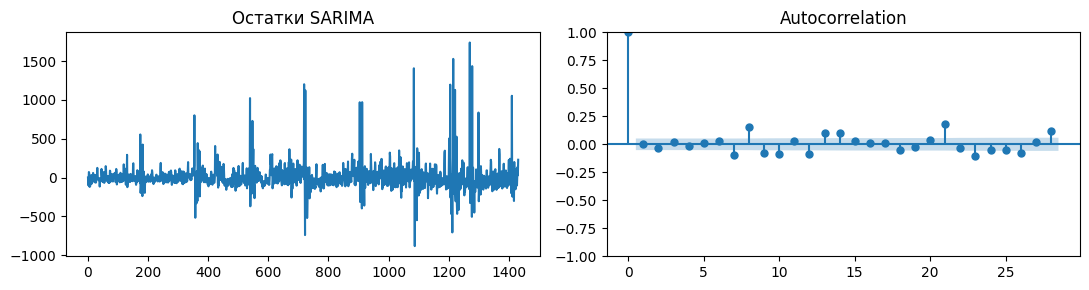

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
residual.plot(ax=axes[0], title='Остатки SARIMA')
plot_acf(residual, lags=28, ax=axes[1])
plt.tight_layout()
plt.show()

In [ ]:
acorr_ljungbox(residual, return_df=True)

,lb_stat,lb_pvalue
1,0.069816,7.916045e-01
2,1.855602,3.954222e-01
3,2.398831,4.938523e-01
4,2.653060,6.174532e-01
5,2.779565,7.339250e-01
6,3.954930,6.827757e-01
7,16.925254,1.788457e-02
8,51.877877,1.777003e-08
9,60.929835,8.871150e-10
10,72.293409,1.596281e-11


🐀 **Что вы можете сказать об остатках модели?**

In [ ]:
check_on_valid('SARIMA', forecast, 'AutoARIMA')

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
SARIMA,238.33,375.29,23.86,17.48


Изменение MAE относительно наивного: -15.68 тыс. ед.


🐀 **Что вы можете сказать о качестве прогноза?**

## SARIMAX


**SARIMAX** (Seasonal AutoRegressive Integrated Moving Average with eXogenous regressors) — расширение SARIMA, которое включает внешние регрессоры.

**Какие значения регрессоров использовать при проверке модели?**

По Hyndman и Athanasopoulos, возможны 2 подхода:

* **Ex-post:** подставляем фактические цены на нефть из проверочного периода. Узнаём, как модель продаж работает, если будущий регрессор известен точно.
* **Ex-ante:** подставляем прогноз цены нефти или сценарий, заданный по доступной на тот момент истории. Проверяем всю систему прогнозирования, включая ошибку будущего регрессора.

Например, в условной модели $\hat y=100+5x$ ошибка прогноза цены нефти $x$ на 10 долларов изменит прогноз продаж на 50 единиц. Коэффициенты уже обученной модели не меняются — меняется её прогноз. Значит, ошибка продаж может возникнуть и из-за модели продаж, и из-за неточного прогноза нефти.

Предлагается сравнивать обе проверки, чтобы понять источник ошибок. Ex-post полезна для изучения модели, ex-ante — для оценки прогноза, который можно получить на практике. В обоих случаях обучаем модель продаж только на прошлом; фактические будущие продажи не используем.

Для праздников и дней недели разницы нет: их даты известны заранее. Ниже для нефти используем ex-ante со сценарием «последняя известная цена». В кросс-валидации этот сценарий будем задавать заново в каждой точке отсечения.

[Hyndman и Athanasopoulos, Forecasting: Principles and Practice, §7.6](https://otexts.com/fpp3/forecasting-regression.html).

Добавим к SARIMA календарь праздников и цену нефти. Будущие значения регрессоров передадим через `X_df`.

Пропуски в котировках заполним последней известной ценой: это позволяет согласовать их календарь с ежедневными продажами.

In [ ]:
oil = pd.read_csv('oil.csv', parse_dates=['date']).set_index('date')[['dcoilwtico']]
oil.columns = ['oil']
oil = oil.reindex(sales.index).ffill()
oil.head()

,oil
ds,
2013-01-02,93.14
2013-01-03,92.97
2013-01-04,93.12
2013-01-05,93.12
2013-01-06,93.12


Возьмём национальные праздники: учтём переносы и уберём дубли. Отметим также 2 дня перед праздником — покупатели могут закупаться заранее. Непредсказуемые события, например землетрясение, в календарь будущих событий не включаем.

In [ ]:
holidays_source = pd.read_csv('holidays_events.csv', parse_dates=['date'])
holidays_source = holidays_source.loc[
    holidays_source['locale'].eq('National')
    & holidays_source['type'].isin(['Holiday', 'Transfer'])
    & ~holidays_source['transferred'].astype(bool)
].copy()
holiday_dates = pd.DatetimeIndex(holidays_source['date'].unique())
preholiday_dates = holiday_dates - pd.Timedelta(days=1)
preholiday_dates = preholiday_dates.union(holiday_dates - pd.Timedelta(days=2))

In [ ]:
def make_regressors(dates, cutoff):
    dates = pd.DatetimeIndex(dates)
    # После cutoff используем только последнюю известную цену.
    known_oil = oil['oil'].where(oil.index <= cutoff).ffill()
    return pd.DataFrame({'unique_id': 'sales', 'ds': dates,
                         'oil': known_oil.reindex(dates).to_numpy(),
                         'holiday': dates.isin(holiday_dates).astype(int),
                         'pre_holiday': (dates.isin(preholiday_dates) & ~dates.isin(holiday_dates)).astype(int)})

regressors_train = make_regressors(train.ds, train.ds.max())
regressors_valid = make_regressors(valid.ds, train.ds.max())
train_with_reg = train.merge(regressors_train, on=['unique_id', 'ds'], validate='one_to_one')
regressors_valid.head()

,unique_id,ds,oil,holiday,pre_holiday
0,sales,2016-12-04,51.7,0,0
1,sales,2016-12-05,51.7,0,0
2,sales,2016-12-06,51.7,0,0
3,sales,2016-12-07,51.7,0,0
4,sales,2016-12-08,51.7,0,0


Посмотрим на историю цен на нефть и проверим, уменьшает ли этот регрессор ошибку прогноза продаж. Улучшение точности само по себе не доказывает причинное влияние нефти.

In [ ]:
px.line(regressors_train, x='ds', y='oil', title='Цена нефти на train', template='plotly_white').show()

In [ ]:
sf_with_reg = StatsForecast(models=[AutoARIMA(**arima_options)], freq='D')
forecast_with_reg = sf_with_reg.forecast(df=train_with_reg, h=forecast_horizon, X_df=regressors_valid)
plot_valid(forecast_with_reg, 'AutoARIMA', 'SARIMAX: календарь и сценарий нефти')
check_on_valid('SARIMAX', forecast_with_reg, 'AutoARIMA')

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
SARIMAX,237.06,373.23,23.74,17.49


Изменение MAE относительно наивного: -16.96 тыс. ед.


# Prophet

Теперь построим ещё одну модель  — Prophet. Она позволяет отдельно задать тренд, сезонности и эффекты праздников.

Для аддитивной модели Prophet:

$$y(t)=g(t)+s(t)+h(t)+\varepsilon_t.$$

* **Тренд $g(t)$** — кусочно-линейная или кусочно-логистическая функция. Логистическая кривая $g(t)=\frac{C}{1+\exp(-k(t-b))}$ описывает рост с насыщением: при приближении к пределу $C$ рост замедляется. В точках изменения может меняться скорость роста.
* **Сезонность $s(t)$** — повторяющиеся колебания, например недельные и годовые. Моделируются рядами Фурье.
* **Праздники $h(t)$** — эффекты заданных событий: праздников, распродаж и других специальных периодов. Задаются индикаторными переменными. Обычные выходные учитывает недельная сезонность.
* **Ошибка $\varepsilon_t$** — часть наблюдения, не объяснённая компонентами. Предполагается нормальная случайная ошибка с нулевым средним.

[Статья Taylor и Letham](https://peerj.com/preprints/3190.pdf).

Посмотрим, как складывается прогноз. Это условный пример: тренд + недельная сезонность + предпраздничный эффект. Случайную ошибку в точечный прогноз не добавляем.

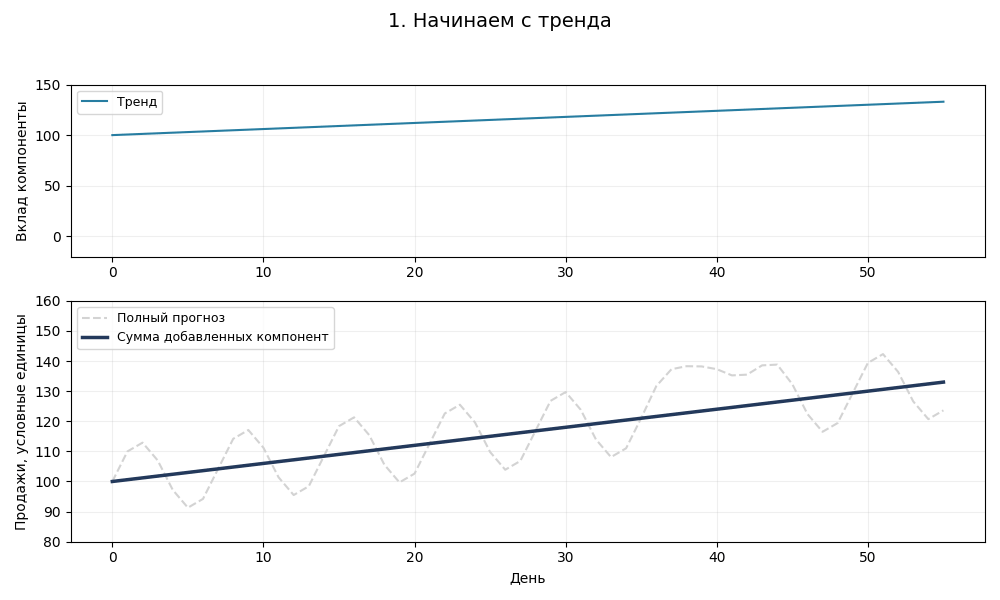

In [ ]:
t = np.arange(56)
trend_demo = 100 + 0.6 * t
season_demo = 12 * np.sin(2 * np.pi * t / 7)
holiday_demo = 25 * np.exp(-0.5 * ((t - 40) / 1.5) ** 2)
parts = [trend_demo, season_demo, holiday_demo]
colors = ['#277DA1', '#43AA8B', '#F8961E']
labels = ['Тренд', 'Недельная сезонность', 'Предпраздничный эффект']
fig, axes = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={'height_ratios': [1, 1.4]})

def draw_components(frame):
    stage = frame // 4
    for ax in axes:
        ax.clear()
        ax.grid(alpha=0.2)
    for j in range(min(stage + 1, 3)):
        axes[0].plot(t, parts[j], color=colors[j], label=labels[j])
    total = sum(parts[:min(stage + 1, 3)])
    axes[1].plot(t, sum(parts), color='lightgray', linestyle='--', label='Полный прогноз')
    axes[1].plot(t, total, color='#23395B', linewidth=2.5, label='Сумма добавленных компонент')
    axes[0].set_ylim(-20, 150)
    axes[1].set_ylim(80, 160)
    axes[0].legend(loc='upper left', ncol=3, fontsize=9)
    axes[1].legend(loc='upper left', fontsize=9)
    axes[0].set_ylabel('Вклад компоненты')
    axes[1].set_ylabel('Продажи, условные единицы')
    axes[1].set_xlabel('День')
    fig.suptitle(['1. Начинаем с тренда', '2. Добавляем недельный цикл',
                  '3. Добавляем событие', 'Прогноз = тренд + сезонность + событие'][stage], fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

animation = FuncAnimation(fig, draw_components, frames=16, interval=650)
animation.save('prophet_components.gif', writer=PillowWriter(fps=1.5))
plt.close(fig)
display(Image(filename='prophet_components.gif'))

## Базовая модель

Начнём с Prophet с параметрами по умолчанию.

In [ ]:
train_fp = train[['ds', 'y']].copy()
# Даты train и valid: увидим и подгонку на обучении, и прогноз.
future = pd.concat([train[['ds']], valid[['ds']]], ignore_index=True)

In [ ]:
m = fp.Prophet()
m.fit(train_fp)
forecast_prophet = m.predict(future)
plot_valid(forecast_prophet, title='Базовый Prophet')
check_on_valid('Prophet', forecast_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet,189.17,367.26,18.94,12.41


Изменение MAE относительно наивного: -64.85 тыс. ед.


`predict()` возвращает таблицу с трендом, сезонными компонентами, прогнозом `yhat` и границами интервала. По умолчанию показывается 80%-й интервал неопределённости прогноза.

In [ ]:
forecast_prophet

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2013-01-02,352.121344,183.574886,595.180080,352.121344,352.121344,40.440327,40.440327,40.440327,-51.288258,-51.288258,-51.288258,91.728586,91.728586,91.728586,0.0,0.0,0.0,392.561672
1,2013-01-03,352.437421,107.086094,510.435082,352.437421,352.437421,-45.470951,-45.470951,-45.470951,-122.431225,-122.431225,-122.431225,76.960274,76.960274,76.960274,0.0,0.0,0.0,306.966471
2,2013-01-04,352.753499,134.144042,562.433630,352.753499,352.753499,-4.747399,-4.747399,-4.747399,-67.249782,-67.249782,-67.249782,62.502383,62.502383,62.502383,0.0,0.0,0.0,348.006100
3,2013-01-05,353.069576,320.454071,744.745419,353.069576,353.069576,182.858999,182.858999,182.858999,134.287810,134.287810,134.287810,48.571189,48.571189,48.571189,0.0,0.0,0.0,535.928574
4,2013-01-06,353.385653,396.384869,802.190436,353.385653,353.385653,234.112080,234.112080,234.112080,198.748290,198.748290,198.748290,35.363789,35.363789,35.363789,0.0,0.0,0.0,587.497733
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,2016-12-27,816.391357,728.063834,1116.747921,816.199327,816.564074,107.698655,107.698655,107.698655,-65.883617,-65.883617,-65.883617,173.582272,173.582272,173.582272,0.0,0.0,0.0,924.090012
1456,2016-12-28,816.407960,730.664838,1122.034769,816.180903,816.602923,110.646873,110.646873,110.646873,-51.288258,-51.288258,-51.288258,161.935131,161.935131,161.935131,0.0,0.0,0.0,927.054834
1457,2016-12-29,816.424564,650.454178,1049.161922,816.157871,816.644967,26.751110,26.751110,26.751110,-122.431225,-122.431225,-122.431225,149.182334,149.182334,149.182334,0.0,0.0,0.0,843.175674
1458,2016-12-30,816.441167,679.690137,1095.129997,816.141942,816.685264,68.297017,68.297017,68.297017,-67.249782,-67.249782,-67.249782,135.546799,135.546799,135.546799,0.0,0.0,0.0,884.738185


Красная линия на train — значения, рассчитанные уже обученной моделью (in-sample). На valid — прогноз будущих продаж (out-of-sample). Метрики считаем только на valid: хорошая подгонка на train ещё не означает точный прогноз.

In [ ]:
pd.DataFrame(validation_results).set_index('Модель').loc[
    ['Seasonal Naive', 'SARIMA', 'SARIMAX', 'Prophet']].round(2)

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Seasonal Naive,254.02,394.56,25.43,19.29
SARIMA,238.33,375.29,23.86,17.48
SARIMA,238.33,375.29,23.86,17.48
SARIMAX,237.06,373.23,23.74,17.49
Prophet,189.17,367.26,18.94,12.41


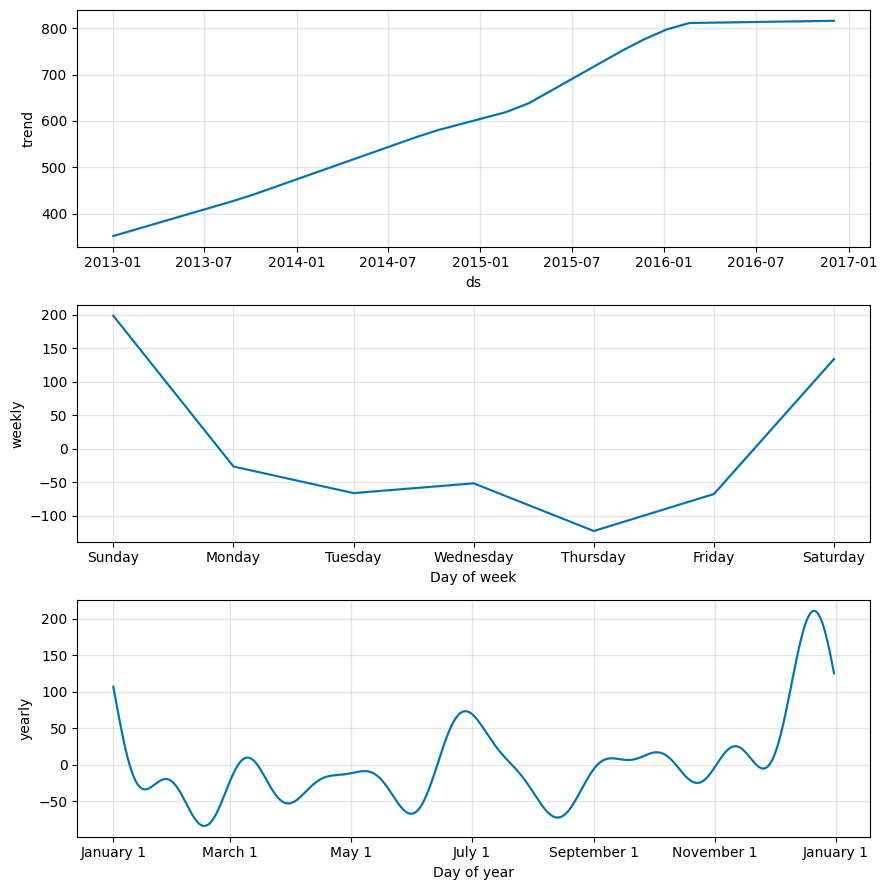

In [ ]:
m.plot_components(m.predict(train_fp[['ds']]))
plt.show()

## Гиперпараметры

Разберём настройки сезонности, тренда и праздников. Сначала сравним два режима сезонности. Затем в отдельных экспериментах будем менять по одному параметру мультипликативной модели; остальные оставим по умолчанию.

Эти эксперименты показывают влияние настроек. Их значения не переносим автоматически в следующую модель — совместный подбор сделаем позже.

[Настройка гиперпараметров Prophet](https://facebook.github.io/prophet/docs/diagnostics.html).

### seasonality_mode

**Бизнес-ситуация:** сеть растёт, и разница между буднями и выходными увеличивается вместе с продажами.

`seasonality_mode='additive'` задаёт сезонность в единицах продаж, `'multiplicative'` — относительно уровня тренда. Попробуем мультипликативный вариант.

In [ ]:
m_2 = fp.Prophet(seasonality_mode='multiplicative')
m_2.fit(train_fp)
forecast_2 = m_2.predict(future)
plot_valid(forecast_2, title='Prophet: мультипликативная сезонность')
check_on_valid('Prophet: multiplicative', forecast_2)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: multiplicative,195.94,380.12,19.62,12.93


Изменение MAE относительно наивного: -58.07 тыс. ед.


In [ ]:
pd.DataFrame(validation_results).set_index('Модель').loc[
    ['SARIMA', 'SARIMAX', 'Prophet', 'Prophet: multiplicative']].round(2)

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
SARIMA,238.33,375.29,23.86,17.48
SARIMA,238.33,375.29,23.86,17.48
SARIMAX,237.06,373.23,23.74,17.49
Prophet,189.17,367.26,18.94,12.41
Prophet: multiplicative,195.94,380.12,19.62,12.93


### yearly_seasonality, weekly_seasonality, fourier_order

`yearly_seasonality` и `weekly_seasonality` включают годовую и недельную сезонности:

* `'auto'` — Prophet включает сезонность с учётом длины истории и частоты наблюдений.
* `True` / `False` — включить / выключить.
* Положительное целое число — задать порядок Фурье.

[Подробнее в документации](https://facebook.github.io/prophet/docs/seasonality,_holiday_effects,_and_regressors.html#fourier-order-for-seasonalities).

Prophet описывает сезонность суммой синусов и косинусов — рядом Фурье.

**Порядок Фурье** определяет сложность кривой внутри периода. По умолчанию для года он равен 10, для недели — 3. Больший порядок позволяет описать более сложный сезонный рисунок, но не делает его разным в каждом году.

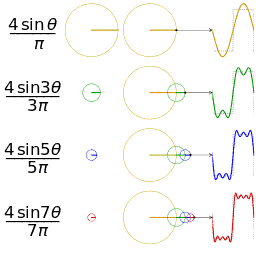

Для своей сезонности в `add_seasonality()` задаём:

* `period` — длительность цикла в днях: например, 7 для недели или 365.25 для года. Даже для часовых данных период задаётся в днях.
* `fourier_order` — число пар синусов и косинусов. При значении 2 получаем четыре коэффициента, при 10 — двадцать.

Чем больше коэффициентов, тем сложнее может быть кривая. Но вместе с этим растёт риск подстроиться под случайные колебания train.

Сравним годовые порядки 2, 10 и 25 по ошибкам на valid. Порядок 10 уже использован в модели с мультипликативной сезонностью; в двух новых вариантах изменим только порядок.

In [ ]:
for order in [2, 25]:
    model_fourier = fp.Prophet(seasonality_mode='multiplicative', yearly_seasonality=order)
    model_fourier.fit(train_fp)
    prediction = model_fourier.predict(future)
    plot_valid(prediction, title=f'Порядок Фурье годовой сезонности: {order}')
    check_on_valid(f'Prophet: Fourier {order}', prediction)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: Fourier 2,232.13,410.69,23.24,15.83


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Изменение MAE относительно наивного: -21.88 тыс. ед.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: Fourier 25,182.01,361.36,18.23,11.25


Изменение MAE относительно наивного: -72.00 тыс. ед.


### seasonality_prior_scale

**Априорное распределение** задаёт, какие значения коэффициентов модель считает более вероятными до учёта данных. При обучении эта информация используется вместе с данными.

Для сезонных коэффициентов $\beta_j$ используется нормальное распределение:

$$
\beta_j \sim N(0, \sigma^2)
$$

Здесь $\sigma$ — значение параметра `seasonality_prior_scale`.

Малый `seasonality_prior_scale` задаёт узкое распределение около нуля и сильнее ограничивает сезонные эффекты. Большой — широкое распределение и более слабое ограничение. По умолчанию значение равно 10.

На графике — распределения возможных коэффициентов, **не самих продаж**. Затем сравним несколько настроек по ошибкам на valid.

In [ ]:
x_prior = np.linspace(-3, 3, 1000)
fig = px.line(title='seasonality_prior_scale: нормальное распределение сезонного коэффициента')
for scale, color in [(0.1, 'blue'), (0.5, 'green'), (1, 'red')]:
    fig.add_scatter(x=x_prior, y=stats.norm.pdf(x_prior, loc=0, scale=scale),
                    mode='lines', name=f'scale = {scale}', line=dict(color=color))
fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_xaxes(title_text='Значение сезонного коэффициента β')
fig.update_yaxes(title_text='Плотность вероятности')
fig.show()

**Бизнес-ситуация:** модель принимает случайные всплески продаж за повторяющийся сезонный рисунок. Усилим регуляризацию: уменьшим `seasonality_prior_scale`.

In [ ]:
for prior in [0.001, 0.01, 25]:
    model_season = fp.Prophet(seasonality_mode='multiplicative', seasonality_prior_scale=prior)
    model_season.fit(train_fp)
    prediction = model_season.predict(future)
    plot_valid(prediction, title=f'seasonality_prior_scale = {prior}')
    check_on_valid(f'Prophet: season prior {prior}', prediction)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: season prior 0.001,258.95,391.08,25.93,19.38


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Изменение MAE относительно наивного: +4.93 тыс. ед.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: season prior 0.01,208.98,368.78,20.93,14.22


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Изменение MAE относительно наивного: -45.04 тыс. ед.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: season prior 25,195.64,380.02,19.59,12.88


Изменение MAE относительно наивного: -58.38 тыс. ед.


### n_changepoints, changepoint_range

По умолчанию Prophet использует кусочно-линейный тренд (`growth='linear'`). Его наклон может меняться в потенциальных точках изменения:

* `n_changepoints=25` — число таких точек.
* `changepoint_range=0.8` — точки размещаются в первых 80% обучающей истории.

При обучении Prophet оценивает изменение наклона в каждой точке. Список точек можно задать вручную через `changepoints`.

[Подробнее в документации](https://facebook.github.io/prophet/docs/trend_changepoints.html).

In [ ]:
print('Default params:\n')
print(f'n_changepoints = {m.n_changepoints}\n')

print(f'changepoint_range = {m.changepoint_range}\n')

Default params:

n_changepoints = 25

changepoint_range = 0.8



Благодаря регуляризации изменения наклона во многих потенциальных точках близки к нулю. На графике отмечаются только изменения, превышающие порог функции визуализации, — это не отбор по p-value.

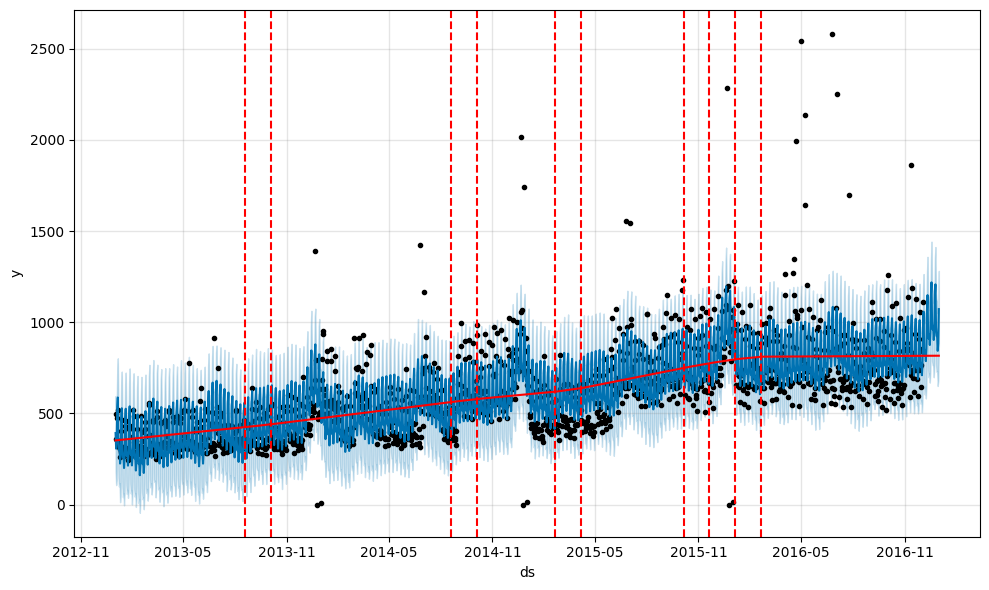

In [ ]:
fig1 = m.plot(forecast_prophet)
a = add_changepoints_to_plot(fig1.gca(), m, forecast_prophet)

**Бизнес-ситуация:** после открытия новых магазинов темп роста продаж мог измениться. Точки изменения позволяют модели сменить наклон тренда, но не устанавливают причину изменения.

🐀 **Что произойдет, если вы измените n_changepoints (установите параметр в 4 или 100)?**

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


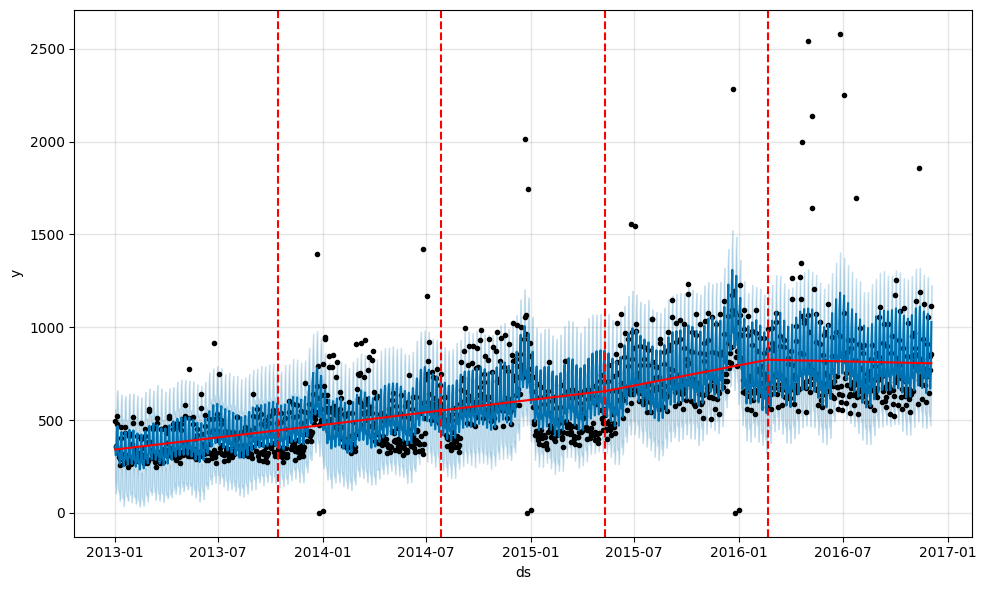

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: changepoints 4,195.16,379.59,19.54,12.82


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Изменение MAE относительно наивного: -58.86 тыс. ед.


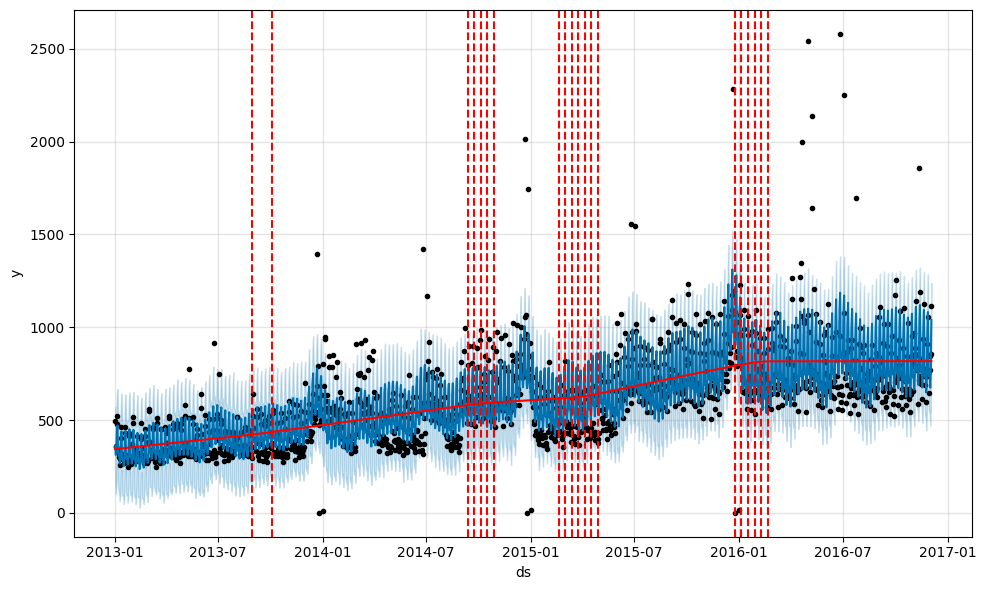

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: changepoints 100,197.62,380.92,19.79,13.11


Изменение MAE относительно наивного: -56.40 тыс. ед.


In [ ]:
for count in [4, 100]:
    model_trend = fp.Prophet(seasonality_mode='multiplicative', n_changepoints=count)
    model_trend.fit(train_fp)
    prediction = model_trend.predict(future)
    history_prediction = model_trend.predict(train_fp[['ds']])
    fig = model_trend.plot(history_prediction)
    add_changepoints_to_plot(fig.gca(), model_trend, history_prediction)
    plt.show()
    check_on_valid(f'Prophet: changepoints {count}', prediction)

🐀 **Почему нам может потребоваться установить changepoint_range в 0.95?**

In [ ]:
m_9 = fp.Prophet(seasonality_mode='multiplicative', changepoint_range=0.95)
m_9.fit(train_fp)
forecast_9 = m_9.predict(future)
plot_valid(forecast_9, title='Точки изменения в первых 95% истории')
check_on_valid('Prophet: range 0.95', forecast_9)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: range 0.95,194.18,378.66,19.44,12.67


Изменение MAE относительно наивного: -59.84 тыс. ед.


### changepoint_prior_scale

В каждой потенциальной точке Prophet оценивает изменение наклона тренда — $\delta_j$. Для этих изменений задаётся априорное распределение Лапласа:

$$\delta_j \sim \operatorname{Laplace}(0,\tau)$$


Здесь $\tau$ — значение параметра `changepoint_prior_scale`.

При малом $\tau$ распределение узкое: сильнее ограничиваются изменения наклона. При большом $\tau$ распределение шире: модель допускает более резкие изменения тренда. По умолчанию $\tau=0.05$.

In [ ]:
x_prior = np.linspace(-0.5, 0.5, 1001)
fig = px.line(title='changepoint_prior_scale: распределение Лапласа для изменения наклона')
for scale, color in [(0.01, 'blue'), (0.05, 'green'), (0.2, 'red')]:
    fig.add_scatter(x=x_prior, y=stats.laplace.pdf(x_prior, loc=0, scale=scale),
                    mode='lines', name=f'scale = {scale}', line=dict(color=color))
fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_xaxes(title_text='Изменение наклона δ')
fig.update_yaxes(title_text='Плотность вероятности')
fig.show()

На оси x — изменение наклона $\delta$ в масштабе, который Prophet использует при обучении. Это не изменение продаж в тысячах единиц.

In [ ]:
print('Default params:\n')

print(f'changepoint_prior_scale = {m.changepoint_prior_scale}\n')

Default params:

changepoint_prior_scale = 0.05



Ниже сравним `changepoint_prior_scale=0.001` и `0.5` по ошибкам на valid. Чем меньше значение, тем сильнее ограничены изменения наклона.

Для начала настройки авторы рекомендуют диапазон [0.001, 0.5]. По моему опыту, можно попробовать и более широкие границы — например, до 1. [Рекомендации авторов](https://facebook.github.io/prophet/docs/diagnostics.html).

In [ ]:
for prior in [0.001, 0.5]:
    model_prior = fp.Prophet(seasonality_mode='multiplicative', changepoint_prior_scale=prior)
    model_prior.fit(train_fp)
    prediction = model_prior.predict(future)
    plot_valid(prediction, title=f'changepoint_prior_scale = {prior}')
    check_on_valid(f'Prophet: trend prior {prior}', prediction)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: trend prior 0.001,214.87,384.63,21.52,15.34


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Изменение MAE относительно наивного: -39.14 тыс. ед.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: trend prior 0.5,212.44,388.3,21.27,14.62


Изменение MAE относительно наивного: -41.58 тыс. ед.


### holidays, holidays_prior_scale

**Бизнес-ситуация:** покупки могут расти перед праздником и снижаться в сам праздник. Учтём не только дату события, но и дни перед ним.

В таблице праздников Prophet нужны 2 столбца:

* **holiday** — название праздника, строка.
* **ds** — дата, тип datetime.

Дополнительно можно задать окно влияния события:

* **lower_window** — смещение начала окна в днях. Например, -2 включает два дня перед праздником.
* **upper_window** — смещение конца окна. Например, 1 включает следующий день.

По умолчанию оба значения равны 0: учитывается только сам праздник. Для прогноза нужны также даты будущих праздников.

Вернёмся к модели с мультипликативной сезонностью и добавим праздники с двумя днями перед ними. Используем уже подготовленный календарь национальных праздников.

In [ ]:
holidays_df = holidays_source[['date', 'description']].drop_duplicates().rename(
    columns={'date': 'ds', 'description': 'holiday'})
holidays_df['lower_window'] = -2
holidays_df['upper_window'] = 0
holidays_df.head()

,ds,holiday,lower_window,upper_window
14,2012-08-10,Primer Grito de Independencia,-2,0
20,2012-10-12,Traslado Independencia de Guayaquil,-2,0
21,2012-11-02,Dia de Difuntos,-2,0
22,2012-11-03,Independencia de Cuenca,-2,0
37,2012-12-25,Navidad,-2,0


In [ ]:
m_12 = fp.Prophet(seasonality_mode='multiplicative', holidays=holidays_df)
m_12.fit(train_fp)
forecast_12 = m_12.predict(future)
plot_valid(forecast_12, title='Prophet: мультипликативная сезонность + праздники')
check_on_valid('Prophet: + праздники', forecast_12)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: + праздники,159.35,282.21,15.96,12.95


Изменение MAE относительно наивного: -94.67 тыс. ед.


In [ ]:
pd.DataFrame(validation_results).set_index('Модель').loc[
    ['Prophet', 'Prophet: multiplicative', 'Prophet: + праздники']].round(2)

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet,189.17,367.26,18.94,12.41
Prophet: multiplicative,195.94,380.12,19.62,12.93
Prophet: + праздники,159.35,282.21,15.96,12.95


`holidays_prior_scale` ограничивает праздничные эффекты: чем меньше значение, тем сильнее регуляризация. По умолчанию — 10. Этот параметр включим в дальнейший подбор.

## Регрессоры

Добавим нефть к модели с мультипликативной сезонностью и праздниками через `add_regressor('oil')`.

Столбец `oil` нужен и для обучения, и для прогноза. На train используем фактические цены, на valid — последнюю известную цену, как в SARIMAX.

In [ ]:
train_fp_with_reg = train[['ds', 'y']].merge(regressors_train[['ds', 'oil']], on='ds', validate='one_to_one')
oil_for_prediction = pd.concat([regressors_train, regressors_valid], ignore_index=True)
future_with_reg = future.merge(oil_for_prediction[['ds', 'oil']], on='ds', validate='one_to_one')

In [ ]:
m_13 = fp.Prophet(seasonality_mode='multiplicative', holidays=holidays_df)
m_13.add_regressor('oil')
m_13.fit(train_fp_with_reg)
forecast_13 = m_13.predict(future_with_reg)
plot_valid(forecast_13, title='Prophet: мультипликативная сезонность + праздники + нефть')
check_on_valid('Prophet: + нефть', forecast_13)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet: + нефть,170.11,285.45,17.03,14.06


Изменение MAE относительно наивного: -83.91 тыс. ед.


## Модель с учётом бизнеса

Собрали модель по шагам: мультипликативная сезонность → праздники → нефть. Сравним все шаги на valid, включая SARIMA и SARIMAX.

Добавление компоненты не обязательно уменьшает ошибку. Пока сохраним эту модель как кандидат для совместного подбора настроек.

In [ ]:
business_params = {'seasonality_mode': 'multiplicative'}
m_final = m_13
forecast_final = forecast_13

pd.DataFrame(validation_results).set_index('Модель').loc[
    ['Seasonal Naive', 'SARIMA', 'SARIMAX', 'Prophet', 'Prophet: multiplicative',
     'Prophet: + праздники', 'Prophet: + нефть']].round(2)

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Seasonal Naive,254.02,394.56,25.43,19.29
SARIMA,238.33,375.29,23.86,17.48
SARIMA,238.33,375.29,23.86,17.48
SARIMAX,237.06,373.23,23.74,17.49
Prophet,189.17,367.26,18.94,12.41
Prophet: multiplicative,195.94,380.12,19.62,12.93
Prophet: + праздники,159.35,282.21,15.96,12.95
Prophet: + нефть,170.11,285.45,17.03,14.06


In [ ]:
fig = px.line(title='От базового Prophet к модели с бизнес-компонентами')
fig.add_scatter(x=train.ds, y=train.y, mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=valid.ds, y=valid.y, mode='lines', name='valid', line=dict(color='green'))
fig.add_scatter(x=forecast_prophet.ds, y=forecast_prophet.yhat, mode='lines', name='Базовый Prophet', line=dict(color='orange'))
fig.add_scatter(x=forecast_final.ds, y=forecast_final.yhat, mode='lines', name='Prophet: сезонность + праздники + нефть', line=dict(color='red'))
fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_yaxes(title_text='Продажи, тыс. ед.')
fig.show()

## Итоги по Prophet

- Обсудили регрессионную модель прогнозирования Prophet, построили базовую модель
- Разобрали настройки тренда и сезонности
- Добавили праздники и регрессоры
- Сравнили подгонку на train и прогнозы на valid

Одного периода valid недостаточно для выбора. Далее повторим обучение и прогноз для нескольких прошлых периодов.

# Тюнинг модели

## Кросс-валидация

**Кросс-валидация** (Cross Validation, CV) проверяет модель на нескольких разделениях данных.

**Для временных рядов обучение всегда в прошлом относительно проверяемого периода.** В отличие от обычного K-fold, случайно перемешивать даты нельзя.

* **Расширяющееся окно:** начало обучения неизменно, конец сдвигается вперёд — история накапливается.
* **Скользящее окно:** сдвигаются обе границы — длина истории остаётся постоянной.

Для Favorita используем расширяющееся окно: в каждой точке заново обучаем модель и прогнозируем следующие 28 дней.

В анимации синий участок — обучение, оранжевый — следующие 28 дней. Вверху история накапливается, внизу модель использует только последние 60 дней. Это схема; ниже для Favorita возьмём более длинную историю.

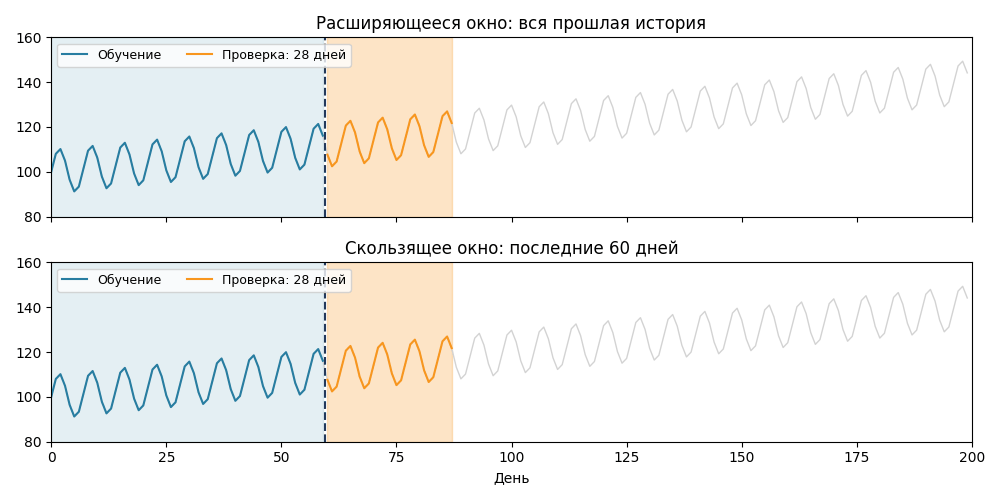

In [ ]:
days = np.arange(200)
demo_y = 100 + 0.2 * days + 10 * np.sin(2 * np.pi * days / 7)
cutoffs_demo = [60, 88, 116, 144, 172]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

def draw_cv(frame):
    cutoff = cutoffs_demo[frame // 3]
    for ax, rolling in zip(axes, [False, True]):
        ax.clear()
        start = max(0, cutoff - 60) if rolling else 0
        ax.plot(days, demo_y, color='lightgray', linewidth=1)
        ax.axvspan(start, cutoff - 1, color='#277DA1', alpha=0.12)
        ax.axvspan(cutoff, cutoff + 27, color='#F8961E', alpha=0.25)
        ax.plot(days[start:cutoff], demo_y[start:cutoff], color='#277DA1', label='Обучение')
        ax.plot(days[cutoff:cutoff + 28], demo_y[cutoff:cutoff + 28], color='#F8961E', label='Проверка: 28 дней')
        ax.axvline(cutoff - 0.5, color='#23395B', linestyle='--')
        ax.set_title('Скользящее окно: последние 60 дней' if rolling else 'Расширяющееся окно: вся прошлая история')
        ax.set_xlim(0, 200)
        ax.set_ylim(80, 160)
        ax.legend(loc='upper left', ncol=2, fontsize=9)
    axes[-1].set_xlabel('День')
    fig.tight_layout()

animation = FuncAnimation(fig, draw_cv, frames=15, interval=700)
animation.save('time_series_cv.gif', writer=PillowWriter(fps=1.4))
plt.close(fig)
display(Image(filename='time_series_cv.gif'))

Метод Prophet `cross_validation()` принимает длительности:

* **initial** — минимальная длина первой обучающей истории; по умолчанию 3 × horizon.
* **horizon** — период прогноза после точки отсечения (`cutoff`), последней даты обучения.
* **period** — шаг между точками отсечения; по умолчанию horizon / 2.

Например, `'180 days'` — 180 календарных дней, а не обязательно 180 строк. При автоматически выбранных точках первая история может быть немного длиннее `initial`.

Проверим модель Prophet с праздниками и нефтью через встроенную `cross_validation()`. Она сама выбирает точки отсечения и переобучает модель на прошлом.

Зададим минимум три года для обучения, шаг 90 дней и горизонт 28 дней. Исторические значения нефти берутся из таблицы: это **ex-post** проверка, как обсуждали после SARIMAX.

🐀 **Что мы делаем в кросс-валидации ниже, на основе параметров initial, period и horizon?**

In [ ]:
train_all_fp = train_all[['ds', 'y']].merge(
    make_regressors(train_all.ds, train_all.ds.max())[['ds', 'oil']], on='ds')

m_cv = fp.Prophet(holidays=holidays_df, **business_params)
m_cv.add_regressor('oil')
m_cv.fit(train_all_fp)

df_cv = cross_validation(m_cv, initial='1095 days', period='90 days', horizon='28 days')

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

Результат содержит дату `ds`, факт `y`, прогноз `yhat`, границы интервала и точку отсечения `cutoff`.

Если проверочные периоды пересекаются, одна дата может встречаться несколько раз с прогнозами из разных точек. Здесь шаг между точками больше горизонта, поэтому периоды не пересекаются.

In [ ]:
df_cv[['ds', 'y', 'yhat', 'cutoff']]

,ds,y,yhat,cutoff
0,2016-03-09,694.645849,776.478205,2016-03-08
1,2016-03-10,572.491857,675.115140,2016-03-08
2,2016-03-11,664.893513,761.212312,2016-03-08
3,2016-03-12,898.101110,1008.348249,2016-03-08
4,2016-03-13,954.980330,1093.716153,2016-03-08
...,...,...,...,...
107,2016-12-27,842.474490,1016.252862,2016-12-03
108,2016-12-28,951.533714,1028.880669,2016-12-03
109,2016-12-29,894.108237,917.310839,2016-12-03
110,2016-12-30,1163.643038,977.594761,2016-12-03


`performance_metrics()` рассчитывает ошибки по результатам CV. Параметр `rolling_window` задаёт долю прогнозов для усреднения после сортировки по расстоянию от cutoff до ds. При `rolling_window=1` получаем общую метрику по всем проверочным периодам.

In [ ]:
performance_metrics(df_cv, rolling_window=1)[['horizon', 'mae', 'rmse']]

INFO:prophet:Skipping MAPE because y close to 0


,horizon,mae,rmse
0,28 days,203.717318,279.481516


## Grid search

**Grid search** — перебор заданной сетки гиперпараметров. Каждую комбинацию проверяем на одинаковых периодах CV и выбираем ту, у которой меньше средняя ошибка.

Лучший вариант в сетке не обязательно окажется лучшим на новых данных. Большая сетка требует много вычислений: модель обучается заново для каждой комбинации и каждой точки отсечения.

In [ ]:
param_grid = {
    'changepoint_prior_scale': [0.01, 0.1],
    'seasonality_prior_scale': [0.1, 10.0],
    'seasonality_mode': ['additive', 'multiplicative'],
    'holidays_prior_scale': [1.0, 10.0]
}
all_params = [dict(zip(param_grid, values)) for values in itertools.product(*param_grid.values())]
len(all_params)

16

🐀 **Сколько моделей мы будем тестировать?**

Здесь 16 комбинаций. Каждую обучаем заново во всех периодах CV Prophet. Для выбора используем MAE: она учитывает и дни с нулевыми продажами. Праздники и нефть остаются во всех моделях.

In [ ]:
tuning_rows = []
for params in tqdm(all_params):
    model_cv = fp.Prophet(holidays=holidays_df, **params)
    model_cv.add_regressor('oil')
    model_cv.fit(train_all_fp)
    cv = cross_validation(model_cv, initial='1095 days', period='90 days', horizon='28 days')
    tuning_rows.append({**params, 'CV MAE': np.abs(cv.y - cv.yhat).mean()})

  0%|          | 0/16 [00:00<?, ?it/s]INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:02<00:43,  2.90s/it]INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

 12%|█▎        | 2/16 [00:05<00:37,  2.66s/it]INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


...

 88%|████████▊ | 14/16 [00:50<00:07,  3.86s/it]INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

 94%|█████████▍| 15/16 [00:54<00:04,  4.13s/it]INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:58<00:00,  3.65s/it]


In [ ]:
tuning_results = pd.DataFrame(tuning_rows).sort_values('CV MAE')
tuning_results

,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,holidays_prior_scale,CV MAE
12,0.10,10.0,additive,1.0,176.914802
9,0.10,0.1,additive,10.0,176.923684
8,0.10,0.1,additive,1.0,177.834951
13,0.10,10.0,additive,10.0,179.674747
5,0.01,10.0,additive,10.0,181.703255
0,0.01,0.1,additive,1.0,182.327380
1,0.01,0.1,additive,10.0,184.363103
4,0.01,10.0,additive,1.0,184.386886
3,0.01,0.1,multiplicative,10.0,200.550669
7,0.01,10.0,multiplicative,10.0,202.034140


In [ ]:
best_params = tuning_results.iloc[0][list(param_grid)].to_dict()
best_params

{'changepoint_prior_scale': 0.1,
 'seasonality_prior_scale': 10.0,
 'seasonality_mode': 'additive',
 'holidays_prior_scale': 1.0}

## Выбранные настройки

На графике ниже посмотрим прогноз с выбранными настройками. Это **не новая независимая проверка на valid**: этот период уже участвовал в CV при подборе.

Независимой проверкой будет test. После неё параметры не меняем.

In [ ]:
m_tuned = fp.Prophet(holidays=holidays_df, **best_params)
m_tuned.add_regressor('oil')
m_tuned.fit(train_fp_with_reg)
forecast_tuned = m_tuned.predict(future_with_reg)
plot_valid(forecast_tuned, title='Prophet после подбора гиперпараметров')

m_tuned_cv = fp.Prophet(holidays=holidays_df, **best_params)
m_tuned_cv.add_regressor('oil')
m_tuned_cv.fit(train_all_fp)
tuned_cv = cross_validation(m_tuned_cv, initial='1095 days', period='90 days', horizon='28 days')

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
base_cv_model = fp.Prophet()
base_cv_model.fit(train_all[['ds', 'y']])
base_cv = cross_validation(base_cv_model, initial='1095 days', period='90 days', horizon='28 days')

prophet_cv_rows = []
for name, frame in [('Prophet', base_cv), ('Prophet adjusted', df_cv), ('Prophet tuned', tuned_cv)]:
    prophet_cv_rows.append({'Модель': name, **forecast_errors(frame.y, frame.yhat)})
prophet_cv_summary = pd.DataFrame(prophet_cv_rows).set_index('Модель').sort_values('MAE')
best_prophet = prophet_cv_summary.index[0]
prophet_cv_summary.round(2)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Making 4 forecasts with cutoffs between 2016-03-08 00:00:00 and 2016-12-03 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
Prophet tuned,176.91,269.50,21.03,20.71
Prophet,192.39,296.86,22.87,21.79
Prophet adjusted,203.72,279.48,24.22,24.28


## Итоги по тюнингу

Выбрали настройки Prophet по средней MAE его кросс-валидации. В таблице сравнили базовый, вручную собранный и настроенный Prophet.

Далее отдельно рассмотрим CV Nixtla. Их точки отсечения не синхронизируем; результат проверим на общем test.

# Статистические модели

Рассмотрим ещё 3 статистические модели: MSTL, AutoTheta и Holt–Winters. Сначала посмотрим прогнозы на valid, затем соберём пайплайн Nixtla с регрессорами.

## MSTL

В начале лекции MSTL использовали только для разложения. **MSTL в StatsForecast** добавляет к нему прогнозирование:

1. Выделить тренд, сезонности и остатки.
2. Удалить сезонности. Останется **тренд + остатки**, а не только сглаженный тренд.
3. Спрогнозировать этот ряд выбранной моделью — у нас AutoARIMA.
4. Повторить каждую сезонную компоненту с помощью Seasonal Naive.
5. Сложить прогнозы. Случайный шум к точечному прогнозу не добавляем.

Для продаж учтём недельный и годовой циклы.

[Подробнее](https://nixtlaverse.nixtla.io/statsforecast/docs/models/multipleseasonaltrend.html).

In [ ]:
sf_example = StatsForecast(models=[MSTL(season_length=[7, 365], trend_forecaster=AutoARIMA(max_p=2, max_q=2, seasonal=False))], freq='D')
prediction = sf_example.forecast(df=train, h=forecast_horizon)
plot_valid(prediction, 'MSTL', 'MSTL: прогноз на valid')
check_on_valid('MSTL', prediction, 'MSTL')

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
MSTL,265.3,438.5,26.56,18.53


Изменение MAE относительно наивного: +11.28 тыс. ед.


## Theta

**Theta** объединяет две части прогноза: долгосрочный тренд и краткосрочные колебания, сглаженные экспоненциальным сглаживанием. Если есть сезонность, её сначала убирают, а затем возвращают в прогноз.

**Когда использовать:** как простой и быстрый ориентир для продаж с плавным трендом и регулярной сезонностью. Например, продажи товарной группы постепенно растут, но колеблются день ото дня. Эффекты конкретных акций и праздников эта модель отдельно не задаёт.

**AutoTheta** выбирает один из четырёх вариантов Theta. В нашем примере учитываем недельный цикл `season_length=7`.

[Подробнее](https://nixtlaverse.nixtla.io/statsforecast/docs/models/autotheta.html).

In [ ]:
sf_example = StatsForecast(models=[AutoTheta(season_length=7)], freq='D')
prediction = sf_example.forecast(df=train, h=forecast_horizon)
plot_valid(prediction, 'AutoTheta', 'AutoTheta: прогноз на valid')
check_on_valid('AutoTheta', prediction, 'AutoTheta')

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
AutoTheta,221.83,393.95,22.21,14.91


Изменение MAE относительно наивного: -32.18 тыс. ед.


## Holt-Winters

**Holt–Winters** — тройное экспоненциальное сглаживание. После каждого наблюдения обновляет три оценки:

* **Уровень:** сколько продаём сейчас.
* **Тренд:** как меняется уровень продаж.
* **Сезонность:** какая поправка нужна для дня недели или месяца.

Новые наблюдения получают больший вес, чем старые. Прогноз продолжает текущий уровень и тренд, добавляя сезонную поправку.

**Когда использовать:** для продаж с регулярным сезонным циклом, когда уровень и тренд постепенно меняются. Например, продажи сети растут, а разница между буднями и выходными сохраняется.

[Hyndman и Athanasopoulos](https://otexts.com/fpp3/holt-winters.html), [StatsForecast Holt–Winters](https://nixtlaverse.nixtla.io/statsforecast/docs/models/holtwinters.html).

В аддитивном варианте сезонная поправка выражена в единицах продаж; в мультипликативном — пропорциональна уровню. Здесь используем аддитивный вариант: в продажах есть нули. Для недельной и годовой сезонностей одновременно удобнее MSTL.

In [ ]:
sf_example = StatsForecast(models=[HoltWinters(season_length=7, error_type='A')], freq='D')
prediction = sf_example.forecast(df=train, h=forecast_horizon)
plot_valid(prediction, 'HoltWinters', 'HoltWinters: прогноз на valid')
check_on_valid('HoltWinters', prediction, 'HoltWinters')

,MAE,RMSE,WAPE(%),MAPE(%)
Модель,,,,
HoltWinters,226.6,407.75,22.69,15.28


Изменение MAE относительно наивного: -27.41 тыс. ед.


## Пайплайн Nixtla

Соберём несколько моделей в одном `StatsForecast` и передадим нефть и календарные регрессоры.

**Регрессоры использует AutoARIMA внутри MSTL:** она прогнозирует ряд после удаления сезонностей — тренд вместе с остатками. Holt–Winters, AutoTheta и Seasonal Naive из этого списка регрессоры не используют.

In [ ]:
train_all_with_reg = train_all.merge(
    make_regressors(train_all.ds, train_all.ds.max()), on=['unique_id', 'ds'])

In [ ]:
models = [
    MSTL(season_length=[7, 365],
         trend_forecaster=AutoARIMA(max_p=2, max_q=2, seasonal=False),
         alias='MSTL_with_reg'),
    HoltWinters(season_length=7, error_type='A'),
    AutoTheta(season_length=7),
    SeasonalNaive(season_length=7)
]
sf_pipeline = StatsForecast(models=models, freq='D')
pipeline_names = [model.alias for model in models]

pipeline_valid = sf_pipeline.forecast(df=train_with_reg, h=forecast_horizon, X_df=regressors_valid)
pipeline_valid.head()

,unique_id,ds,MSTL_with_reg,HoltWinters,AutoTheta,SeasonalNaive
0,sales,2016-12-04,1131.383034,1137.537212,1064.170866,1056.721592
1,sales,2016-12-05,823.184280,809.829312,839.546505,752.583768
2,sales,2016-12-06,757.036419,768.552098,800.158711,645.760508
3,sales,2016-12-07,694.696338,799.221599,814.479177,767.361704
4,sales,2016-12-08,638.627349,709.772378,743.380459,843.603314


In [ ]:
fig = px.line(title='Пайплайн Nixtla: прогноз на valid')
fig.add_scatter(x=train.ds, y=train.y, mode='lines', name='train', line=dict(color='blue'))
fig.add_scatter(x=valid.ds, y=valid.y, mode='lines', name='valid', line=dict(color='green'))
for name, color in zip(pipeline_names, ['red', 'orange', 'purple', 'gray']):
    fig.add_scatter(x=pipeline_valid.ds, y=pipeline_valid[name], mode='lines', name=name, line=dict(color=color))
fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_yaxes(title_text='Продажи, тыс. ед.')
fig.show()

## Кросс-валидация Nixtla

`StatsForecast.cross_validation()` сама формирует окна. Зададим `h=28` — горизонт прогноза, `step_size=28` — шаг и `n_windows=4` — число окон.

С регрессорами из исторической таблицы получаем **ex-post** оценку. Это отдельная CV Nixtla, не синхронизированная с Prophet.

In [ ]:
crossvalidation_df = sf_pipeline.cross_validation(
    df=train_all_with_reg,
    h=28,
    step_size=28,
    n_windows=4
)
crossvalidation_df.head()

,unique_id,ds,cutoff,y,MSTL_with_reg,HoltWinters,AutoTheta,SeasonalNaive
0,sales,2016-09-11,2016-09-10,1017.369224,1026.659506,1052.510752,978.708145,1109.985858
1,sales,2016-09-12,2016-09-10,678.776459,790.000892,736.797132,762.039655,813.763295
2,sales,2016-09-13,2016-09-10,603.427947,723.956879,701.253379,723.859574,751.583025
3,sales,2016-09-14,2016-09-10,624.262072,745.513126,716.802814,735.571783,738.543916
4,sales,2016-09-15,2016-09-10,568.324813,660.549841,639.980135,668.222498,595.849299


In [ ]:
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse

def evaluate_cross_validation(df, metric):
    model_names = df.drop(columns=['unique_id', 'ds', 'cutoff', 'y']).columns.tolist()
    evaluations = []
    for cutoff in df['cutoff'].unique():
        result = evaluate(df[df['cutoff'] == cutoff], metrics=[metric], models=model_names)
        evaluations.append(result)
    result = pd.concat(evaluations).groupby('unique_id').mean(numeric_only=True)
    result['best_model'] = result.idxmin(axis=1)
    return result

In [ ]:
evaluation_cv_mae = evaluate_cross_validation(crossvalidation_df, mae)
best_nixtla = evaluation_cv_mae.loc['sales', 'best_model']
evaluation_cv_mae

,MSTL_with_reg,HoltWinters,AutoTheta,SeasonalNaive,best_model
unique_id,,,,,
sales,120.098556,120.094431,125.600991,156.686398,HoltWinters


In [ ]:
evaluate_cross_validation(crossvalidation_df, rmse)

,MSTL_with_reg,HoltWinters,AutoTheta,SeasonalNaive,best_model
unique_id,,,,,
sales,196.369004,194.600111,198.83143,218.492665,HoltWinters


🐀 **Какая модель лучшая?**

Для выбора в каждом блоке используем MAE: отдельно внутри Prophet и внутри пайплайна Nixtla. Их CV относятся к разным периодам, поэтому по этим числам не выбираем победителя между библиотеками.

Теперь обучим модели на всей истории до конца 2016 года и сравним на одном test: 1–28 января 2017. Будущую нефть зададим на последнем известном уровне — это ex-ante прогноз. По test параметры не подбираем.

In [ ]:
from time import perf_counter

test_predictions = {}
test_rows = []
future_regressors = make_regressors(test.ds, train_all.ds.max())

test_models = models + [
    AutoARIMA(**arima_options, alias='SARIMA'),
    MSTL(season_length=[7, 365], trend_forecaster=AutoARIMA(max_p=2, max_q=2, seasonal=False)),
    AutoARIMA(**arima_options, alias='SARIMAX')
]
for model in test_models:
    start = perf_counter()
    one_model = StatsForecast(models=[model], freq='D')
    if model.alias in ['MSTL_with_reg', 'SARIMAX']:
        prediction = one_model.forecast(df=train_all_with_reg, h=forecast_horizon, X_df=future_regressors)
    else:
        prediction = one_model.forecast(df=train_all, h=forecast_horizon)
    elapsed = perf_counter() - start
    aligned = test.merge(prediction, on=['unique_id', 'ds'])
    test_predictions[model.alias] = aligned[['ds', model.alias]].rename(columns={model.alias: 'yhat'})
    test_rows.append({'Модель': model.alias, **forecast_errors(aligned.y, aligned[model.alias]), 'Время, с': elapsed})

for name, params in [('Prophet', {}), ('Prophet adjusted', business_params), ('Prophet tuned', best_params)]:
    start = perf_counter()
    if name == 'Prophet':
        model_p = fp.Prophet(**params)
        model_p.fit(train_all[['ds', 'y']])
        prediction = model_p.predict(test[['ds']])
    else:
        model_p = fp.Prophet(holidays=holidays_df, **params)
        model_p.add_regressor('oil')
        model_p.fit(train_all_fp)
        prediction = model_p.predict(future_regressors[['ds', 'oil']])
    elapsed = perf_counter() - start
    aligned = test[['ds', 'y']].merge(prediction[['ds', 'yhat']], on='ds')
    test_predictions[name] = aligned[['ds', 'yhat']]
    test_rows.append({'Модель': name, **forecast_errors(aligned.y, aligned.yhat), 'Время, с': elapsed})

test_summary = pd.DataFrame(test_rows).set_index('Модель')
test_summary.round(2)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,MAE,RMSE,WAPE(%),MAPE(%),"Время, с"
Модель,,,,,
MSTL_with_reg,168.18,275.07,19.80,353.89,4.29
HoltWinters,228.17,311.65,26.87,391.09,0.35
AutoTheta,220.92,305.29,26.02,380.11,1.62
SeasonalNaive,306.95,445.74,36.15,37.53,0.01
SARIMA,207.68,247.72,24.46,212.21,2.68
MSTL,168.50,275.09,19.84,353.78,2.59
SARIMAX,209.12,248.47,24.63,209.51,11.49
Prophet,126.09,251.54,14.85,338.97,0.51
Prophet adjusted,135.46,270.47,15.95,383.02,0.95


## Сравнение CV и test

Сравним CV и test отдельно для каждой библиотеки. Ошибки не обязаны совпадать: даты и обучающая история различаются. Для моделей с нефтью есть ещё одна разница — в CV цены известны, а на test используем сценарий.

In [ ]:
prophet_comparison = prophet_cv_summary[['MAE']].rename(columns={'MAE': 'CV MAE'}).join(
    test_summary[['MAE', 'RMSE', 'WAPE(%)', 'MAPE(%)']].add_prefix('Test '))
prophet_comparison.round(2)

,CV MAE,Test MAE,Test RMSE,Test WAPE(%),Test MAPE(%)
Модель,,,,,
Prophet tuned,175.63,120.87,254.67,14.23,358.70
Prophet,192.85,126.21,251.59,14.86,338.93
Prophet adjusted,204.49,136.38,270.80,16.06,383.17


In [ ]:
nixtla_cv_mae = evaluation_cv_mae.loc['sales', pipeline_names].astype(float).rename('CV MAE')
nixtla_comparison = nixtla_cv_mae.to_frame().join(
    test_summary[['MAE', 'RMSE', 'WAPE(%)', 'MAPE(%)']].add_prefix('Test '))
nixtla_comparison.round(2)

,CV MAE,Test MAE,Test RMSE,Test WAPE(%),Test MAPE(%)
MSTL_with_reg,120.10,168.18,275.07,19.80,353.89
HoltWinters,120.09,228.17,311.65,26.87,391.09
AutoTheta,125.60,220.92,305.29,26.02,380.11
SeasonalNaive,156.69,306.95,445.74,36.15,37.53


MAE и RMSE — в тысячах единиц; WAPE и MAPE — в процентах. Время — одно обучение и прогноз на этой машине, без стоимости подбора.

Seasonal Naive повторяет рождественский ноль последней недели на обычных воскресеньях — эффект из примера в начале.

1 января продажи около 12 тыс. единиц, 2 января — 1402 тыс. Малый знаменатель первого дня сильно увеличивает MAPE.

In [ ]:
fig = px.line(title='Test: модели, выбранные в отдельных CV')
fig.add_scatter(x=train_all.ds, y=train_all.y, mode='lines', name='train_all', line=dict(color='blue'))
fig.add_scatter(x=test.ds, y=test.y, mode='lines', name='test', line=dict(color='green'))
for name, color in [(best_prophet, 'red'), (best_nixtla, 'orange'), ('SeasonalNaive', 'gray')]:
    prediction = test_predictions[name]
    fig.add_scatter(x=prediction.ds, y=prediction.yhat, mode='lines', name=name, line=dict(color=color))
fig.update_layout(template='plotly_white', width=1000, height=450)
fig.update_yaxes(title_text='Продажи, тыс. ед.')
fig.show()

CV помогает выбрать настройки внутри каждого блока. На test смотрим, сохранилось ли преимущество, и сравниваем прогнозы на одних датах.

Для закупок важны и последствия ошибок: дефицит товара, излишние запасы и срок поставки. Небольшое улучшение точности стоит сопоставить со стоимостью переобучения и подготовки регрессоров.

# ИТОГИ

- Построили простой сезонный прогноз как ориентир.
- Разобрали компоненты Prophet на бизнес-примерах.
- Проверили настройки на valid и на общей временной кросс-валидации.
- Сравнили Prophet, SARIMA/SARIMAX, MSTL, Theta и Holt–Winters.
- Один раз оценили зафиксированные модели на test.

Пожалуйста, оставьте свой фидбек [тут](https://forms.gle/afizD5qd19o8sfm58) :)